In [1]:
import kagglehub
from kagglehub import KaggleDatasetAdapter
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import datetime as dt

from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

In [2]:
# dataset source: https://www.kaggle.com/datasets/hellbuoy/online-retail-customer-clustering
df = kagglehub.dataset_load(
    KaggleDatasetAdapter.PANDAS,
    "hellbuoy/online-retail-customer-clustering",
    "OnlineRetail.csv",
    pandas_kwargs={"encoding": "ISO-8859-1"},
)

df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,01-12-2010 08:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,01-12-2010 08:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,01-12-2010 08:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,01-12-2010 08:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,01-12-2010 08:26,3.39,17850.0,United Kingdom


In [3]:
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB


,Quantity,UnitPrice,CustomerID
count,541909.000000,541909.000000,406829.000000
mean,9.552250,4.611114,15287.690570
std,218.081158,96.759853,1713.600303
min,-80995.000000,-11062.060000,12346.000000
25%,1.000000,1.250000,13953.000000
50%,3.000000,2.080000,15152.000000
75%,10.000000,4.130000,16791.000000
max,80995.000000,38970.000000,18287.000000


In [4]:
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

## Data Cleaning

In [5]:
df_clean = df.dropna(subset=['CustomerID']).copy()

df_clean = df_clean[(df_clean['Quantity'] > 0) & (df_clean['UnitPrice'] > 0)]

df_clean['CustomerID'] = df_clean['CustomerID'].astype(int).astype(str)
df_clean['InvoiceDate'] = pd.to_datetime(df_clean['InvoiceDate'], format='%d-%m-%Y %H:%M')

df_clean['TotalAmount'] = df_clean['Quantity'] * df_clean['UnitPrice']

print(f"Jumlah baris setelah cleaning: {df_clean.shape[0]}")

Jumlah baris setelah cleaning: 397884


In [6]:
snapshot_date = df_clean['InvoiceDate'].max() + dt.timedelta(days=1)

rfm = df_clean.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (snapshot_date - x.max()).days,
    'InvoiceNo': 'nunique',
    'TotalAmount': 'sum'
}).reset_index()

rfm.columns = ['CustomerID', 'Recency', 'Frequency', 'Monetary']
print("\nHasil Agregasi RFM (5 baris pertama):")
display(rfm.head())

rfm_log = np.log1p(rfm[['Recency', 'Frequency', 'Monetary']])

scaler = StandardScaler()
rfm_scaled_array = scaler.fit_transform(rfm_log)

rfm_scaled = pd.DataFrame(rfm_scaled_array, columns=['Recency', 'Frequency', 'Monetary'])
print("\nHasil Feature Scaling (5 baris pertama):")
display(rfm_scaled.head())


Hasil Agregasi RFM (5 baris pertama):


,CustomerID,Recency,Frequency,Monetary
0,12346,326,1,77183.60
1,12347,2,7,4310.00
2,12348,75,4,1797.24
3,12349,19,1,1757.55
4,12350,310,1,334.40



Hasil Feature Scaling (5 baris pertama):


,Recency,Frequency,Monetary
0,1.461993,-0.955214,3.706225
1,-2.038734,1.074425,1.411843
2,0.373104,0.386304,0.716489
3,-0.623086,-0.955214,0.698739
4,1.424558,-0.955214,-0.618962


## Visualisasi Data

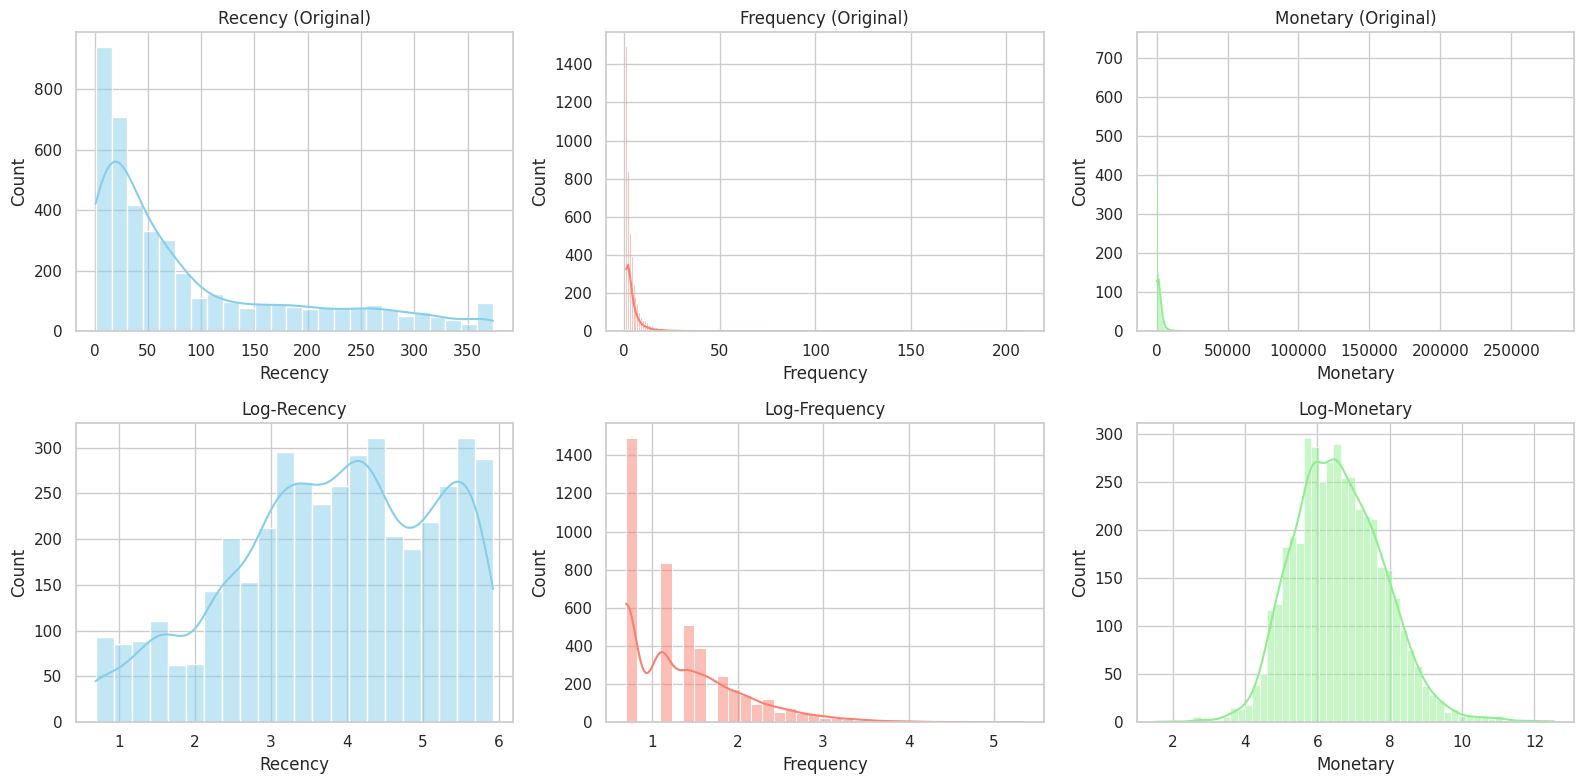

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))

sns.histplot(rfm['Recency'], kde=True, ax=axes[0, 0], color='skyblue').set(title='Recency (Original)')
sns.histplot(rfm['Frequency'], kde=True, ax=axes[0, 1], color='salmon').set(title='Frequency (Original)')
sns.histplot(rfm['Monetary'], kde=True, ax=axes[0, 2], color='lightgreen').set(title='Monetary (Original)')

sns.histplot(rfm_log['Recency'], kde=True, ax=axes[1, 0], color='skyblue').set(title='Log-Recency')
sns.histplot(rfm_log['Frequency'], kde=True, ax=axes[1, 1], color='salmon').set(title='Log-Frequency')
sns.histplot(rfm_log['Monetary'], kde=True, ax=axes[1, 2], color='lightgreen').set(title='Log-Monetary')

plt.tight_layout()
plt.show()

## Hierarchical Clustering

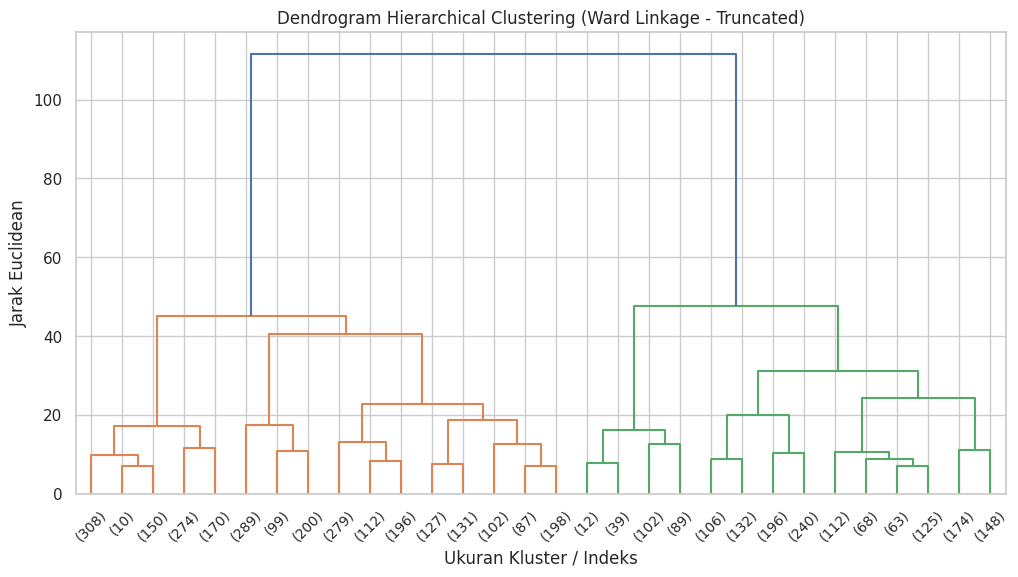

Silhouette Score untuk k=2: 0.4092
Silhouette Score untuk k=3: 0.3526
Silhouette Score untuk k=4: 0.2419
Silhouette Score untuk k=5: 0.2596
Silhouette Score untuk k=6: 0.2462

Jumlah Kluster Optimal Berdasarkan Silhouette Score: k = 2


In [8]:
plt.figure(figsize=(12, 6))
linkage_matrix = linkage(rfm_scaled, method='ward', metric='euclidean')
dendrogram(linkage_matrix, truncate_mode='lastp', p=30, leaf_rotation=45., leaf_font_size=10.)
plt.title('Dendrogram Hierarchical Clustering (Ward Linkage - Truncated)')
plt.xlabel('Ukuran Kluster / Indeks')
plt.ylabel('Jarak Euclidean')
plt.show()

silhouette_scores = {}
k_candidates = range(2, 7)

for k in k_candidates:
    model_eval = AgglomerativeClustering(n_clusters=k, metric='euclidean', linkage='ward')
    cluster_labels = model_eval.fit_predict(rfm_scaled)
    score = silhouette_score(rfm_scaled, cluster_labels)
    silhouette_scores[k] = score
    print(f"Silhouette Score untuk k={k}: {score:.4f}")

optimal_k = max(silhouette_scores, key=silhouette_scores.get)
print(f"\nJumlah Kluster Optimal Berdasarkan Silhouette Score: k = {optimal_k}")

final_model = AgglomerativeClustering(n_clusters=optimal_k, metric='euclidean', linkage='ward')
rfm['Cluster'] = final_model.fit_predict(rfm_scaled)
rfm_scaled['Cluster'] = rfm['Cluster'].astype(str)

## Visualisasi Hasil Kluster

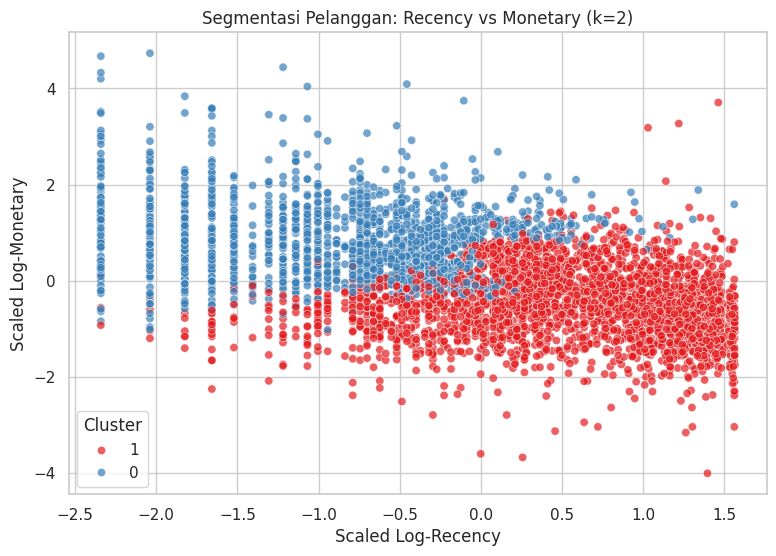


Ringkasan Karakteristik Kluster Pelanggan (Skala Asli):


,Avg_Recency_Days,Avg_Frequency_Orders,Avg_Monetary_Spend,Customer_Count
Cluster,,,,
0,21.24,8.46,4491.27,1606
1,134.45,1.81,621.68,2732


In [9]:
# Scatter Plot Recency vs Monetary
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=rfm_scaled, 
    x='Recency', 
    y='Monetary', 
    hue='Cluster', 
    palette='Set1',
    alpha=0.7
)
plt.title(f'Segmentasi Pelanggan: Recency vs Monetary (k={optimal_k})')
plt.xlabel('Scaled Log-Recency')
plt.ylabel('Scaled Log-Monetary')
plt.legend(title='Cluster')
plt.show()

# Profiling Kluster (Nilai Rata-rata Asli RFM per Kluster)
cluster_summary = rfm.groupby('Cluster').agg({
    'Recency': 'mean',
    'Frequency': 'mean',
    'Monetary': ['mean', 'count']
}).round(2)

cluster_summary.columns = ['Avg_Recency_Days', 'Avg_Frequency_Orders', 'Avg_Monetary_Spend', 'Customer_Count']
print("\nRingkasan Karakteristik Kluster Pelanggan (Skala Asli):")
display(cluster_summary)